## 회귀 모델(알고리즘)
- 회귀 :  연속적인 수치(숫자)를 예측하는 모델
- 분류 vs 회귀 
  - 분류 : 범주(up/down)를 예측하며, 예측이 맞았는지/틀렸느지가 명확함 (혼동행렬, 정확도 등)
  - 회귀 : 연속적인 수치(수익률)를 예측하며, 정확히 맞았다는 개념이 없음! -> 오차의 크기를 측정(MAE, RMSE, R^2 등)
> **회귀에서는 얼마나 가까운가(오차의 크기)**가 가장 중요!
> 참고: **로지시특 회귀**는 이름만 회귀이고, 선형 계산 후 확률을 통해 범주를 판단하는 **분류 모델**임!  

---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from _ml import build_dataset, time_split , FEATURES , SEED
from _style import setup

setup()
pd.set_option("display.width", 130)

df = build_dataset()
train, test, cutoff = time_split(df)

tr = train.sample(15000, random_state=SEED)
te = test.sample(4000, random_state=SEED)

X_train, X_test = tr[FEATURES], te[FEATURES]

# 정답(y)를 두 종류 준비 -> 분류(target_up) / 회귀(target_ret)
y_train_cls, y_test_cls = tr["target_up"], te["target_up"]  # 분류용 정답 : 상승(1)  / 하락(0)
y_train_reg, y_test_reg = tr["target_ret"], te["target_ret"]  # 회귀용 정답 : 수익률(수치)

print(f" * 학습 {len(tr):,}행 ({tr['date'].min().date()} ~ {tr['date'].max().date()})")
print(f" * 테스트 {len(te):,}행 ({te['date'].min().date()} ~ {te['date'].max().date()})")
print(f" * 피처 {len(FEATURES)}개")
print()
print(f"- 분류용 정답(target_up) : {y_train_cls.unique()} (범주)")
print(f"- 회귀용 정답(target_ret) : {y_train_reg.min():.4f} ~ {y_train_reg.max():.4f} (수치)")


 * 학습 15,000행 (2023-10-24 ~ 2026-01-16)
 * 테스트 4,000행 (2026-01-19 ~ 2026-09-07)
 * 피처 7개

- 분류용 정답(target_up) : [0 1] (범주)
- 회귀용 정답(target_ret) : -0.2260 ~ 0.2313 (수치)


- 분류 : y = target_up (0/1) --> RandomForestClassifier
- 회귀 : y = target_ret (수익률) --> RandomForestRegressor

**이름은 동일한 알고리즘이지만, 평가 방법이 완전히 달라짐!**
- RandomForestClassifier => accuracy_score(정확도), f1_score(F1 점수)
- RandomForestRegressor => mean_absolute_error(MAE), mean_squared_error(MSE), RMSE(√MSE), r2_score(R²)

In [4]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import (accuracy_score, f1_score,                         # 분류 평가지표
                             mean_absolute_error, mean_squared_error, r2_score)  # 회귀 평가지표

clf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=SEED, n_jobs=-1)
reg = RandomForestRegressor(n_estimators=100, max_depth=6, random_state=SEED, n_jobs=-1)

# 학습 --> fit(X_train, y_train)
# 분류 모델 학습
clf.fit(X_train, y_train_cls)

# 회귀 모델 학습
reg.fit(X_train, y_train_reg)

# 예측 --> pred = predict(X_test)
# 분류 모델 예측 (pred_cls)
pred_cls = clf.predict(X_test)

# 회귀 모델 예측 (pred_reg)
pred_reg = reg.predict(X_test)


print(f"{'':<14}{'분류':<32}{'회귀'}")
print('-' * 70)
print(f"{'정답예시':<13}{y_test_cls.iloc[0]:<32}{y_test_reg.iloc[0]:.4f}")
print(f"{'예측예시':<13}{pred_cls[0]:<32}{pred_reg[0]:.4f}")
print()
print(f"분류 평가 : 정확도 {accuracy_score(y_test_cls, pred_cls):.4f}"
      f"     F1 {f1_score(y_test_cls, pred_cls):.4f}")

print(f"회귀 평가 : RMSE {np.sqrt(mean_squared_error(y_test_reg, pred_reg)):.6f}"
      f"     R^2 {r2_score(y_test_reg, pred_reg):.4f}")

              분류                              회귀
----------------------------------------------------------------------
정답예시         0                               -0.0068
예측예시         1                               -0.0000

분류 평가 : 정확도 0.4933     F1 0.4269
회귀 평가 : RMSE 0.027389     R^2 -0.0068


In [5]:
# 회귀 예측을 0 기준으로 나누어서 분류를 해본다면? 
reg_to_cls = (pred_reg > 0).astype(int)

print(f"회귀 모델 예측을 0 기준으로 나눈 정확도: "
      f" {accuracy_score(y_test_cls, reg_to_cls):.4f}")
print(f"분류 모델로 학습한 정확도: "
      f" {accuracy_score(y_test_cls, pred_cls):.4f}")

회귀 모델 예측을 0 기준으로 나눈 정확도:  0.4793
분류 모델로 학습한 정확도:  0.4933


---
## LinearRegrssion (선형 회귀)
가장 단순한 선형 회귀 모델. 직선으로 관계를 표현.\
`예측값 = w1*ret_1d + w2*ret_5d + ... + b`

- 학습 : **오차의 제곱합(MSE)** 이 가증 작아지는 가중치(w)와 절편(b)를 찾는 것.
  - w = 가중치(계수) : 다른 피처가 그대로일 때, 해당 피처가 1 증가하면 예측값이 얼마나 변하는지
  - b = 절편(편향)


In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler   # 각 피처의 평균 0, 표준편차 1로 맞춰줌


def make(model):
    return Pipeline([("sc",StandardScaler()), ("m", model)])

lin = make(LinearRegression())

lin.fit(X_train, y_train_reg)

# 절편(b), 계수(w) 확인
coef = pd.Series(lin.named_steps["m"].coef_ ,index=FEATURES).sort_values()
# lin.named_steps["m"] : 모델 객체 추출
# 모델.coef_ : 가중치(계수) 배열

intercept = lin.named_steps["m"].intercept_
# 모델.intercept_ : 절편(편향) 값

print(f"* 절편 (b) : {intercept:.6f}")
print()
print(f"* 가중치 (w) :")
print(coef.round(6).to_string())

* 절편 (b) : -0.000063

* 가중치 (w) :
vol20          -0.000567
ma20_ratio     -0.000507
volume_ratio   -0.000161
range_pct       0.000055
ma5_ratio       0.000117
ret_5d          0.000544
ret_1d          0.000756


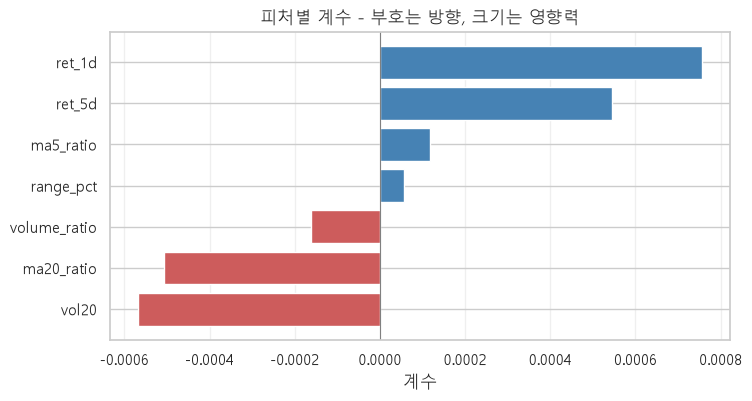

In [8]:
fig, ax = plt.subplots(figsize=(8, 4)) 

colors = ["indianred" if v < 0  else "steelblue" for v in coef.values]

ax.barh(coef.index, coef.values, color = colors)

ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("계수")
ax.set_title("피처별 계수 - 부호는 방향, 크기는 영향력")
ax.grid(alpha=0.3, axis = "x")

plt.show()

**계수(가중치)는 해석을 도와주는 지표**
계수의 부호는 방향 (+ 올리는쪽/ - 내리는 쪽)을, 절댓값은 영향력의 크기를 알려줌\
다만, 피처의 스케일(단위)이 다르면 계수 크기를 직접 비교할 수 없으므로 **스케일링을 먼저** 진행해야 함

또한 피처끼리 서로 비슷하다면(다중 공선성) 계수가 불안정해져서 해석이 틀어질 수 있음.\
(우리 데이터의 계수는 모두 0에 가까운 아주 작은 값이므로, 선형 관계가 거의 없다고 볼 수 있음)

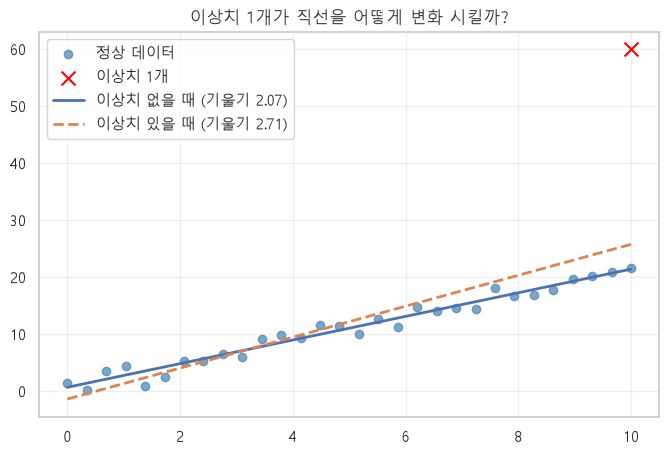

In [11]:
from sklearn.linear_model import LinearRegression

rng = np.random.default_rng(SEED)      # 난수 생성기

x_demo = np.linspace(0, 10, 30)        # 0 ~ 10 구간을 균등하게 나눈 30개의 숫자
# y = 2x + 1 에 노이즈 추가 (평균 0, 표준편차 1.5인 오차 30개)
y_demo = 2 * x_demo + 1 + rng.normal(0, 1.5, 30)

# 이상치 1개 추가 : x = 10 인데 y = 60 (원래대로라면 21 근처 값이어야 함)
x_bad = np.append(x_demo, 10)
y_bad = np.append(y_demo, 60)

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(x_demo, y_demo, color="steelblue", alpha=0.7, label="정상 데이터")
ax.scatter(10, 60, color="red", marker="x", s=100, label="이상치 1개")

# (x값, y값, 선 스타일, 이름)
datas = [
    (x_demo, y_demo, "C0-", "이상치 없을 때"),
    (x_bad, y_bad, "C1--", "이상치 있을 때"),
]

for xs, ys, d, name in datas:
    m = LinearRegression().fit(xs.reshape(-1, 1), ys)

    xx = np.linspace(0, 10, 10)
    ax.plot(xx, m.predict(xx.reshape(-1, 1)), d, lw=2, label=f"{name} (기울기 {m.coef_[0]:.2f})")

ax.legend()
ax.grid(alpha=0.3)
ax.set_title("이상치 1개가 직선을 어떻게 변화 시킬까?")

plt.show()

**이상치 하나가 직선을 끌고가는 것을 확인할 수 있음**

선형 회귀는 오차의 제곱을 최소함. 크게 빗나간 데이터(이상치)가 제곱되면서 영향력이 매우 커짐!